In [47]:
import numpy as np

data = np.load('../../data/processed/dataset_preprocessed.npz')
x = data['X_data']
y = data['Y_data']

In [48]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [132]:
from tensorflow.keras import layers, Model, regularizers


max_length = 25

inputs = layers.Input(shape=(max_length, 250))

x = layers.Bidirectional(layers.LSTM(
    units=6, 
    dropout=0.2, 
    # recurrent_dropout=0.4,
    kernel_regularizer=regularizers.l2(0.001)
))(inputs)

outputs = layers.Dense(1, activation='sigmoid')(x)

model = Model(inputs=inputs, outputs=outputs, name="Bidirectional_LSTM_Sentiment")

model.summary()

Model: "Bidirectional_LSTM_Sentiment"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_25 (InputLayer)     │ (None, 25, 250)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_25                │ (None, 12)             │        12,336 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 1)              │            13 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,349 (48.24 KB)

 Trainable params: 12,349 (48.24 KB)

 Non-trainable params: 0 (0.00 B)

In [133]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    x_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/50
153/153 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.6151 - loss: 0.6790 - val_accuracy: 0.6782 - val_loss: 0.6201 - learning_rate: 0.0010
Epoch 2/50
153/153 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.7516 - loss: 0.5474 - val_accuracy: 0.7217 - val_loss: 0.5813 - learning_rate: 0.0010
Epoch 3/50
153/153 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.7697 - loss: 0.5209 - val_accuracy: 0.7044 - val_loss: 0.5904 - learning_rate: 0.0010
Epoch 4/50
153/153 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.7724 - loss: 0.5103 - val_accuracy: 0.7274 - val_loss: 0.5684 - learning_rate: 0.0010
Epoch 5/50
153/153 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.7726 - loss: 0.5040 - val_accuracy: 0.7348 - val_loss: 0.5608 - learning_rate: 0.0010
Epoch 6/50
153/153 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.7798 - loss: 0.5010 - val_accuracy: 0.7340 - val_loss: 0.5632 - learning_rate: 0.0010
Epoch 7/50
153/153 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.7830 - loss: 0.

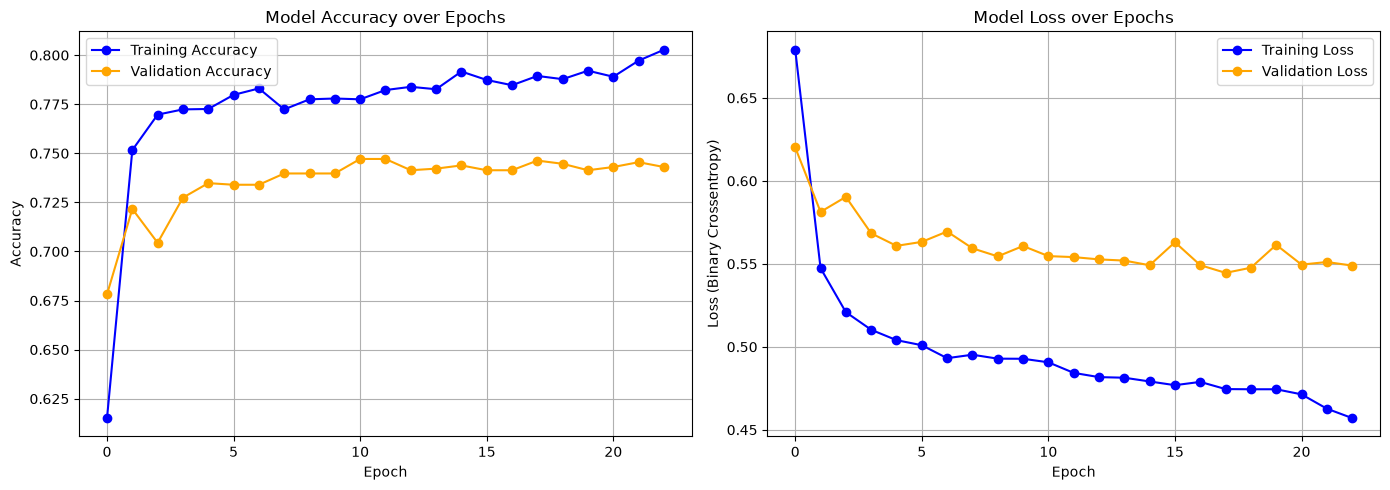

39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step


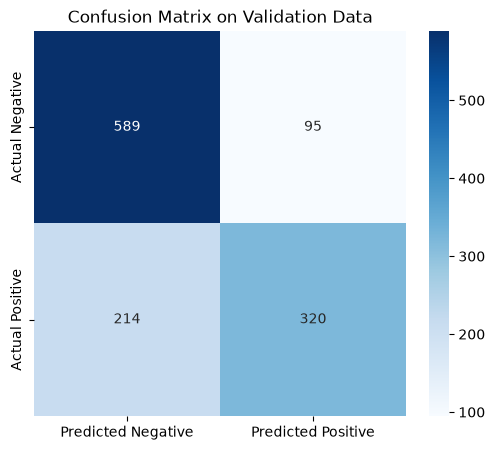

In [134]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# 1. Plot Accuracy and Loss over Epochs
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy Plot
ax1.plot(history.history['accuracy'], label='Training Accuracy', color='blue', marker='o')
ax1.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange', marker='o')
ax1.set_title('Model Accuracy over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True)

# Loss Plot
ax2.plot(history.history['loss'], label='Training Loss', color='blue', marker='o')
ax2.plot(history.history['val_loss'], label='Validation Loss', color='orange', marker='o')
ax2.set_title('Model Loss over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss (Binary Crossentropy)')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

# 2. Generate a Confusion Matrix
# We use the final 20% of the data as a proxy for our validation set to match the validation_split
val_split_index = int(len(x_train) * 0.8)
X_val = x_train[val_split_index:]
Y_val = y_train[val_split_index:]

# Get raw probability predictions from the model
predictions_prob = model.predict(X_val)

# Convert probabilities to binary classes (0 or 1) using a 0.5 threshold
predictions_binary = (predictions_prob > 0.5).astype(int)

# Calculate the confusion matrix
cm = confusion_matrix(Y_val, predictions_binary)

# Plot the confusion matrix using Seaborn
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Predicted Negative', 'Predicted Positive'],
            yticklabels=['Actual Negative', 'Actual Positive'])
plt.title('Confusion Matrix on Validation Data')
plt.show()

## Evaluation

In [135]:
y_pred = model.predict(x_test)


48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


In [136]:
y_pred = (y_pred > 0.5).astype(int)

In [137]:
from sklearn.metrics import accuracy_score

test_accuracy = accuracy_score(y_test, y_pred)
print(test_accuracy)

0.783322390019698
